In [1]:
from NQS import *
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rbm = RBM(
    num_visible=4,
    num_hidden=8,
    seed=0
)

tfi = TFI(
    N=4,
    J=1.0,
    h=2.0
)

mcmc = MCMC(
    n_spins=4,
    seed=1
)

vmc = VMC(
    rbm,
    tfi,
    mcmc
)

sr = SR(
    learning_rate=0.01,
    lambda_reg=1e-3
)

MCMC
  ↓
samples S₁, S₂, ..., Sₖ
  ↓
calculate E_loc(S)
  ↓
calculate O_i(S) = ∂ log ψ / ∂θ_i
  ↓
calculate gradient g
  ↓
calculate FB metric S
  ↓
solve (S + λI) Δθ = -ηg
  ↓
update v, h, W
  ↓
repeat

In [3]:

energy_history = []
for iteration in range(50):

    # sample configurations
    samples = mcmc.sample(
        rbm,
        n_samples=1000,
        burn_in=100
    )

    # calculate local energies
    local_energies = torch.stack([
        vmc.local_energy(s.unsqueeze(0))
        for s in samples
    ]).squeeze()

    # update weights and biases
    sr.update(
        rbm,
        samples,
        local_energies
    )

    # Energy estimate
    energy = local_energies.mean()

    print(
        f"Iteration {iteration}: "
        f"E = {energy.item():.6f}"
    )

    energy_history.append(energy.item())

Iteration 0: E = 7.239473


Iteration 1: E = 7.063807


Iteration 2: E = 4.173982


Iteration 3: E = 2.186114


Iteration 4: E = 9.595355


...

Iteration 45: E = 0.006351


Iteration 46: E = 0.006351


Iteration 47: E = 0.006351


Iteration 48: E = 0.006351


Iteration 49: E = 0.006351


Text(0.5, 1.0, 'N=4, M=8, lr=0.01')

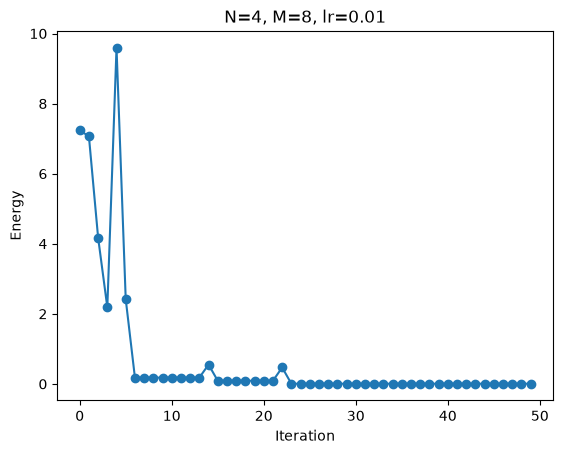

In [4]:
fig = plt.figure()
plt.plot(range(50), energy_history, marker='o', linestyle='-')
plt.xlabel('Iteration')
plt.ylabel('Energy')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')

## Seed sweep

In [5]:
# Important note: num_visible corresponds to number of spins in the TFI chain. 

def minimise_e(seed, n_iterations=50, n_samples=200, burn_in=50,
                            num_visible=4, num_hidden=8, J=1.0, h=2.0,
                            noise_std=0.0):
    rbm = RBM(num_visible=num_visible, num_hidden=num_hidden, seed=seed)
    tfi = TFI(N=num_visible, J=J, h=h)
    mcmc = MCMC(n_spins=num_visible, seed=seed + 1_000_000)
    vmc = VMC(rbm, tfi, mcmc)
    sr = SR(learning_rate=0.01, lambda_reg=1e-3, noise_std=noise_std)

    # reject negative energies: carry forward the last accepted (positive)
    # value. If no positive value has been seen yet, record NaN rather than
    # forcing an early negative value through - some (J, h) regimes never
    # produce a positive raw energy at all, and forcing that value through
    # would silently defeat the rejection filter.
    energy_history = []
    last_accepted = None
    for iteration in range(n_iterations):
        samples = mcmc.sample(rbm, n_samples=n_samples, burn_in=burn_in)
        local_energies = torch.stack([
            vmc.local_energy(s.unsqueeze(0)) for s in samples
        ]).squeeze()
        sr.update(rbm, samples, local_energies)
        energy = local_energies.mean().item()

        if energy > 0:
            last_accepted = energy
            energy_history.append(energy)
        elif last_accepted is not None:
            energy_history.append(last_accepted)
        else:
            energy_history.append(float('nan'))

    return energy_history


def run_seed(seed, **kwargs):
    return minimise_e(seed, **kwargs)[-1]


n_seeds = 50
seed_energies = [run_seed(seed) for seed in range(n_seeds)]

In [6]:
import pandas as pd

seed_energies_arr = np.array(seed_energies)
n_nan = np.isnan(seed_energies_arr).sum()

stats_table = pd.DataFrame({
    "Statistic": ["Mean", "Min", "Max", "Variance", "Excluded (NaN) seeds"],
    "Energy (iteration 50)": [
        np.nanmean(seed_energies_arr),
        np.nanmin(seed_energies_arr),
        np.nanmax(seed_energies_arr),
        np.nanvar(seed_energies_arr),
        n_nan,
    ],
})
stats_table

,Statistic,Energy (iteration 50)
0,Mean,0.803074
1,Min,0.027858
2,Max,9.950079
3,Variance,3.304786
4,Excluded (NaN) seeds,0.000000


## Seed sweep with gradient noise

 `delta_theta = -eta * S_lambda^-1 * g + epsilon`, with
`epsilon_i ~ N(0, sigma^2)`

 `noise_std=0.01`.

In [7]:
noise_std = 0.01
seed_energies_noisy = [
    run_seed(seed, noise_std=noise_std) for seed in range(n_seeds)
]

In [8]:
seed_energies_noisy_arr = np.array(seed_energies_noisy)
n_nan_noisy = np.isnan(seed_energies_noisy_arr).sum()

stats_table_noisy = pd.DataFrame({
    "Statistic": ["Mean", "Min", "Max", "Variance", "Excluded (NaN) seeds"],
    "Energy (iteration 50)": [
        np.nanmean(seed_energies_noisy_arr),
        np.nanmin(seed_energies_noisy_arr),
        np.nanmax(seed_energies_noisy_arr),
        np.nanvar(seed_energies_noisy_arr),
        n_nan_noisy,
    ],
})
stats_table_noisy

,Statistic,Energy (iteration 50)
0,Mean,1.076202
1,Min,0.014143
2,Max,18.276535
3,Variance,8.768687
4,Excluded (NaN) seeds,0.000000


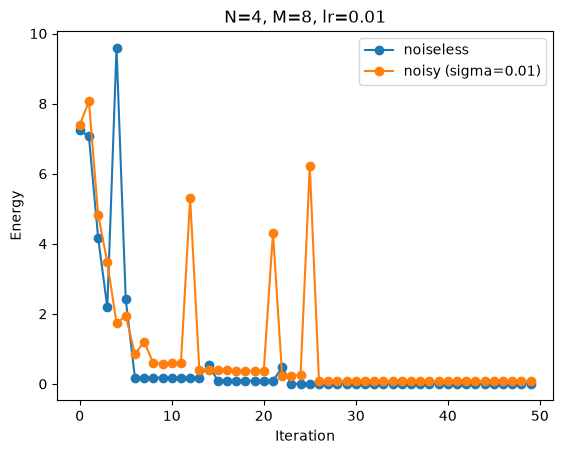

In [9]:
# Single-seed trajectory with noise, for comparison against the noiseless run above
noisy_history_demo = minimise_e(seed=0, noise_std=noise_std)

fig = plt.figure()
plt.plot(energy_history, marker='o', linestyle='-', label='noiseless')
plt.plot(noisy_history_demo, marker='o', linestyle='-', label=f'noisy (sigma={noise_std})')
plt.xlabel('Iteration')
plt.ylabel('Energy')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.legend()

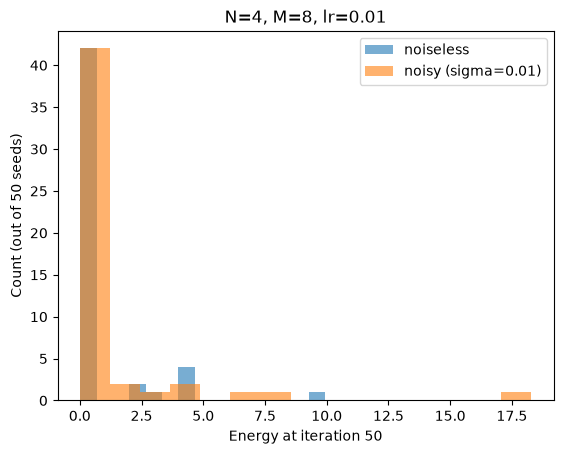

In [10]:
# Distribution of final (iteration-50) energies across the 50 seeds, noiseless vs noisy
# (NaN entries - seeds that never produced a positive energy - are excluded)
fig = plt.figure()
plt.hist(seed_energies_arr[~np.isnan(seed_energies_arr)], bins=15, alpha=0.6, label='noiseless')
plt.hist(seed_energies_noisy_arr[~np.isnan(seed_energies_noisy_arr)], bins=15, alpha=0.6, label=f'noisy (sigma={noise_std})')
plt.xlabel('Energy at iteration 50')
plt.ylabel('Count (out of 50 seeds)')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.legend()

## Sweep over h/J ratio: minimum energy across 50 seeds

For fixed `J=1.0`, sweep the transverse-field ratio `h/J`; record minimum energy

In [11]:
J_fixed = 1.0
ratios = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0]
sweep_settings = dict(n_iterations=20, n_samples=100, burn_in=20)

min_energy_noiseless = []
min_energy_noisy = []

for ratio in ratios:
    h = ratio * J_fixed

    energies_noiseless = np.array([
        run_seed(seed, J=J_fixed, h=h, **sweep_settings)
        for seed in range(n_seeds)
    ])
    energies_noisy = np.array([
        run_seed(seed, J=J_fixed, h=h, noise_std=noise_std, **sweep_settings)
        for seed in range(n_seeds)
    ])

    min_energy_noiseless.append(np.nanmin(energies_noiseless))
    min_energy_noisy.append(np.nanmin(energies_noisy))

    print(f"h/J = {ratio}: min(noiseless) = {min_energy_noiseless[-1]:.6f} "
          f"({np.isnan(energies_noiseless).sum()} NaN seeds), "
          f"min(noisy) = {min_energy_noisy[-1]:.6f} "
          f"({np.isnan(energies_noisy).sum()} NaN seeds)")

h/J = 0.1: min(noiseless) = 0.008600 (11 NaN seeds), min(noisy) = 0.005412 (11 NaN seeds)


h/J = 0.25: min(noiseless) = 0.000400 (9 NaN seeds), min(noisy) = 0.001539 (9 NaN seeds)


h/J = 0.5: min(noiseless) = 0.022982 (8 NaN seeds), min(noisy) = 0.003863 (7 NaN seeds)


h/J = 0.75: min(noiseless) = 0.027625 (6 NaN seeds), min(noisy) = 0.014976 (6 NaN seeds)


h/J = 1.0: min(noiseless) = 0.074979 (3 NaN seeds), min(noisy) = 0.211298 (4 NaN seeds)


...

h/J = 2.0: min(noiseless) = 0.081423 (0 NaN seeds), min(noisy) = 0.250773 (0 NaN seeds)


h/J = 3.0: min(noiseless) = 0.040959 (0 NaN seeds), min(noisy) = 0.030222 (0 NaN seeds)


h/J = 5.0: min(noiseless) = 0.000422 (0 NaN seeds), min(noisy) = 0.000278 (0 NaN seeds)


h/J = 7.0: min(noiseless) = 0.003038 (0 NaN seeds), min(noisy) = 0.000884 (0 NaN seeds)


h/J = 10.0: min(noiseless) = 0.000030 (0 NaN seeds), min(noisy) = 0.000011 (0 NaN seeds)


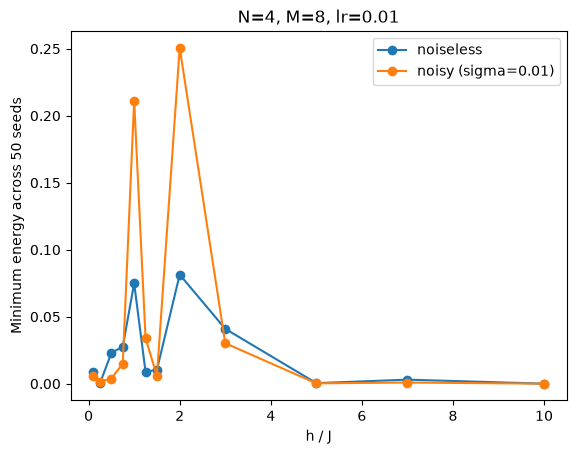

In [12]:
fig = plt.figure()
plt.plot(ratios, min_energy_noiseless, marker='o', linestyle='-', label='noiseless')
plt.plot(ratios, min_energy_noisy, marker='o', linestyle='-', label=f'noisy (sigma={noise_std})')
plt.xlabel('h / J')
plt.ylabel('Minimum energy across 50 seeds')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.legend()